# KHAI PHÁ DỮ LIỆU - LAB 2
### Sinh viên: Ngô Minh Khôi
### MSSV: 6451071037


## 1. Chuẩn bị các thư viện cần thiết

In [1]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split
import seaborn as sns
from PIL import Image, ImageOps

print("Đã import thành công tất cả các thư viện cần thiết.")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Đã import thành công tất cả các thư viện cần thiết.


## 2. Tải dữ liệu có sẵn trong thư viện sklearn

In [2]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
digits = datasets.load_digits()
print("Số lượng mẫu ảnh:", len(digits.images))
print("Kích thước mỗi ảnh:", digits.images[0].shape)
print("Các lớp nhãn:", np.unique(digits.target))


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Số lượng mẫu ảnh: 1797
Kích thước mỗi ảnh: (8, 8)
Các lớp nhãn: [0 1 2 3 4 5 6 7 8 9]


## 3. Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


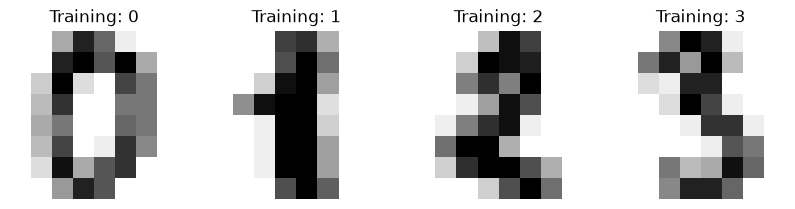

In [3]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
_, axes = plt.subplots(1, 4, figsize=(10, 4))
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f'Training: {label}', fontsize=12)
plt.show()


## 4. Chuyển đổi mỗi đối tượng hình ảnh (ma trận 8x8) thành ma trận 1x64

In [4]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
print("Kích thước dữ liệu sau khi biến đổi phẳng:", data.shape)


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Kích thước dữ liệu sau khi biến đổi phẳng: (1797, 64)


## 5. Chia dữ liệu thành hai phần: huấn luyện 80%, kiểm thử 20% (shuffle=False)

In [5]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False
)
print("Kích thước tập huấn luyện X_train:", X_train.shape)
print("Kích thước tập kiểm thử X_test:", X_test.shape)


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Kích thước tập huấn luyện X_train: (1437, 64)
Kích thước tập kiểm thử X_test: (360, 64)


## 6. Xây dựng cây ID3 (criterion='entropy', random_state=33) và huấn luyện mô hình

In [6]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)
classifier.fit(X_train, y_train)

print("Mô hình Cây quyết định ID3 đã được huấn luyện xong:")
print(classifier)


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Mô hình Cây quyết định ID3 đã được huấn luyện xong:
DecisionTreeClassifier(criterion='entropy', random_state=33)


## 7. Dự đoán nhãn dữ liệu cho tập kiểm thử

In [7]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
predicted = classifier.predict(X_test)
print("Một số nhãn dự đoán đầu tiên:", predicted[:15])
print("Một số nhãn thực tế đầu tiên:", y_test[:15])


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Một số nhãn dự đoán đầu tiên: [2 3 4 5 6 7 8 9 0 9 5 5 6 5 0]
Một số nhãn thực tế đầu tiên: [2 3 4 5 6 7 8 9 0 9 5 5 6 5 0]


## 8. Biểu diễn một vài kết quả dự đoán với hình ảnh

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


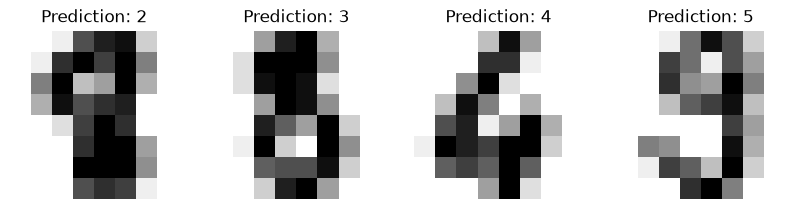

In [8]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
_, axes = plt.subplots(1, 4, figsize=(10, 4))
images_and_predictions = list(zip(digits.images[n_samples // 2:], predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f'Prediction: {prediction}', fontsize=12)
plt.show()


## 9. Đánh giá thông số đạt được và Ma trận nhầm lẫn

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037
Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):

              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360

Confusion matrix:
 [[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  

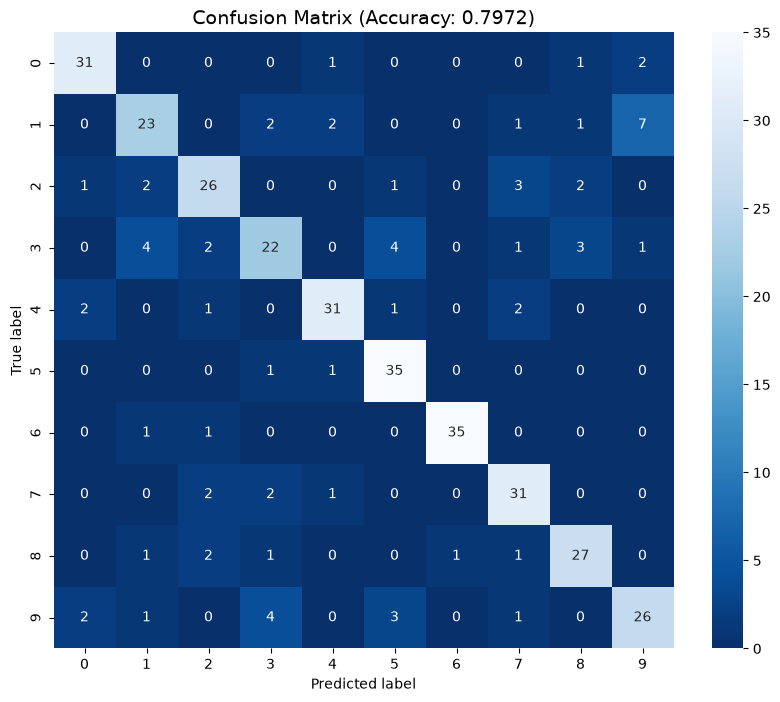

In [9]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
print(f"Classification report for classifier {classifier}:\n")
print(metrics.classification_report(y_test, predicted))

cm = metrics.confusion_matrix(y_test, predicted)
print("Confusion matrix:\n", cm)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues_r')
plt.title(f"Confusion Matrix (Accuracy: {metrics.accuracy_score(y_test, predicted):.4f})", fontsize=14)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()


## 10. Thực nghiệm nhận diện ảnh chữ số viết tay thực tế
Chụp ảnh chữ số viết tay, tiền xử lý và đưa vào mô hình nhận diện.

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


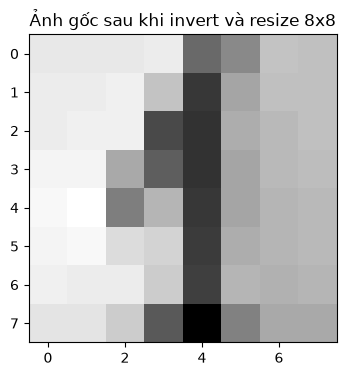

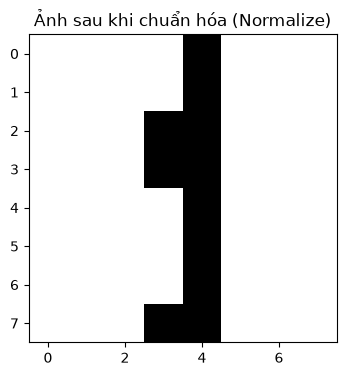

KẾT QUẢ DỰ ĐOÁN CHỮ SỐ VIẾT TAY: [1]


In [10]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
# Đọc ảnh mẫu chữ số viết tay test_image_Bai7.jpg
img = Image.open('datasets/test_image_Bai7.jpg').convert("L").resize((8, 8))
img = ImageOps.invert(img)
im2arr = np.array(img)

# Hiển thị ảnh sau khi đọc và resize
plt.figure(figsize=(4, 4))
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("Ảnh gốc sau khi invert và resize 8x8")
plt.show()

# Làm rõ nét ảnh và chuẩn hóa nhị phân
img1d = im2arr.reshape([1, 64])
img1d[img1d > 109] = 155
img1d[img1d < 110] = 0

plt.figure(figsize=(4, 4))
plt.imshow(img1d.reshape(8, 8), cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("Ảnh sau khi chuẩn hóa (Normalize)")
plt.show()

# Tiến hành nhận diện bằng cây ID3
y_pred_real = classifier.predict(img1d)
print(f"KẾT QUẢ DỰ ĐOÁN CHỮ SỐ VIẾT TAY: [{y_pred_real[0]}]")
